# Retail Anomaly Detection System
Unsupervised anomaly detection on ~1M order / customer / product / payment lines for a fictional Delhi supermarket chain.

**Run order:** `python train_models.py` first (creates data, models, thresholds), then this notebook.

## 1. Business definition (agreed with the mock business owner)

| Anomaly | What it means to the business |
|---|---|
| price_error | Unit price 10x/100x too high or too low vs the product's recent price (decimal slip, GST mix-up) |
| qty_spike | Quantity far beyond what is normal for that category / customer |
| discount_abuse | Discount of 60-90% where the product normally sells at 0-20% |
| odd_hour_high_value | Large cash / wallet / gift-card sale between 00:00 and 05:00 |
| guest_refund | Refund with no customer ID |
| rare_combo | Category and payment pairing that almost never occurs (e.g. gift card on fresh produce) |
| duplicate_charge | Identical line recorded twice in the same minute |

**Cost of a false alarm:** Rs 50 (about 5 reviewer minutes). **Cost of a missed anomaly:** Rs 2,000 on average.
**Manual baseline:** staff scan about 2% of records today. **Target:** alerts at most 1% of records (workload cut by half), precision at top 1% of at least 60%, every alert explained.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from anomaly_core import *

pd.set_option("display.width", 160)
print(BUSINESS_RULES)

{'false_alarm_cost_inr': 50, 'missed_anomaly_cost_inr': 2000, 'manual_review_rate': 0.02, 'alert_rate_cap': 0.01, 'target_precision': 0.6}


## 2. Data and quality problems

In [2]:
df = pd.read_csv("data/transactions.csv", parse_dates=["ts"], dtype={"customer_id": "object", "price_basis": "object", "anomaly_type": "object"})
df["anomaly_type"] = df["anomaly_type"].fillna("")
print(df.shape)
print("guest checkouts (no customer ID):", round(df["customer_id"].isna().mean(), 3))
print("price basis unknown (GST status missing):", round(df["price_basis"].isna().mean(), 3))
print("distinct raw category spellings:", df["category_raw"].nunique(), "-> canonical:", df["category_raw"].str.lower().str.strip().map(CAT_MAP).nunique())
print(df[df["category_raw"].str.lower().str.contains("snack|munch")].groupby(df["ts"].dt.to_period("M"))["category_raw"].agg(lambda s: sorted(s.str.strip().str.title().unique())).to_string())
print("true anomaly rate (synthetic ground truth):", round(df["is_anomaly"].mean(), 4))

(999999, 13)
guest checkouts (no customer ID): 0.3
price basis unknown (GST status missing): 0.15


distinct raw category spellings: 56 -> canonical: 10
ts
2026-01                [Snacks]
2026-02                [Snacks]
2026-03                [Snacks]
2026-04     [Snacks & Munchies]
2026-05     [Snacks & Munchies]
2026-06     [Snacks & Munchies]
2026-07     [Snacks & Munchies]
2026-08    [Munchies & Namkeen]
2026-09    [Munchies & Namkeen]
2026-10    [Munchies & Namkeen]
Freq: M
true anomaly rate (synthetic ground truth): 0.013


## 3. Cleaning and behavioural features
* Category renames (twice) and spelling noise are mapped to one canonical category.
* Prices are converted to ex-GST. Where the basis is missing, the candidate (with or without GST) closer to the product's reference price is used.
* Guests have no history, so they are compared with peers (category) instead of a personal baseline.
* Features: deviation from a rolling 50-transaction product price baseline, customer quantity baseline, category peer z-scores, discount deviation, rarity of category x payment, hour x amount, guest x amount, refund and duplicate flags.

In [3]:
state = fit_state(df)
d = build_features(df, state).sort_values("line_id").reset_index(drop=True)
y = d["is_anomaly"].values
d[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(2)

,mean,std,min,50%,max
price_dev,0.01,1.74,-30.00,0.00,30.00
qty_dev_cust,0.02,0.77,-8.75,0.00,15.00
qty_peer_z,-0.11,0.68,-0.67,0.00,15.00
amt_peer_z,0.08,1.05,-10.12,-0.02,14.00
disc_dev,0.49,0.70,-0.50,0.00,9.00
rar_cat_pay,3.49,0.79,2.25,3.30,8.59
rar_hour_amt,4.92,0.27,4.51,4.89,13.82
rar_guest_amt,2.94,0.52,2.64,2.67,10.32
log_amount,4.98,0.97,0.10,4.93,13.87
is_guest,0.30,0.46,0.00,0.00,1.00


## 4. Model comparison
Isolation Forest, Local Outlier Factor (novelty mode, fitted on a 20k sample), an autoencoder (12-5-12 tanh network, reconstruction error) and a robust z-score baseline (largest absolute deviation across the five z features). LOF is scored on a 100k random evaluation sample, so all four models are compared on the same rows.

In [4]:
det = Detector().fit(d)
ev = d.sample(100_000, random_state=11)
yev = ev["is_anomaly"].values
raw_ev = det.raw_scores(ev)
raw_ev["lof"] = lof_scores(d, ev, det, n_neighbors=35)
rows = []
for k, v in raw_ev.items():
    rows.append({"model": k, "precision_at_1pct": precision_at_top(v, yev, 0.01), "recall_at_1pct": recall_at_top(v, yev, 0.01)})
cmp = pd.DataFrame(rows).set_index("model").round(3)
cmp

,precision_at_1pct,recall_at_1pct
model,,
iforest,0.572,0.445
autoencoder,0.636,0.495
robust_z,0.693,0.540
lof,0.660,0.514


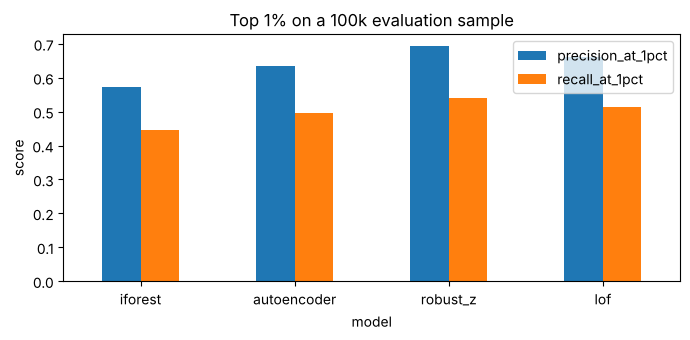

In [5]:
ax = cmp.plot.bar(figsize=(7, 3.5))
ax.set_ylabel("score")
ax.set_title("Top 1% on a 100k evaluation sample")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. 300 labelled cases, ensemble rule, contamination and threshold
The 300 labels are a stratified audit sample (100 from the robust z top 1%, 100 from the 1-5% band, 100 from the rest). Each case carries a sampling weight, so precision can be estimated for any model. Half the labels tune (ensemble rule, alert rate), half validate. The ensemble rule is chosen from mean of model percentiles, mean of the top two, or the maximum, so a record flagged strongly by any one specialist model is not diluted by the others.

In [6]:
raw = det.raw_scores(d)
lab_idx, lab_y, lab_w = make_labelled_sample(raw["robust_z"], y, 300)
perm = np.random.default_rng(0).permutation(300)
tune_i, hold_i = perm[:150], perm[150:]
method, mgrid = tune_combiner(det, d, lab_idx[tune_i], lab_y[tune_i], lab_w[tune_i])
ens, raw = det.score(d, method)
print(mgrid.round(3).to_string(index=False))
q, table = tune_alert_rate(ens, lab_idx[tune_i], lab_y[tune_i], lab_w[tune_i])
print("ensemble rule:", method, "| chosen alert rate (contamination):", q)
table.round(3)

method  weighted_p_at_1pct  mean_p_over_0.5_to_2pct
  mean                 0.5                    0.564
  top2                 0.8                    0.696
   max                 0.8                    0.725
ensemble rule: max | chosen alert rate (contamination): 0.01


,alert_rate,precision_est,est_true_alerts,est_recall,expected_cost_inr
0,0.003,1.000,2999.997,0.368,1.028535e+07
1,0.005,0.955,4772.727,0.586,6.751252e+06
2,0.008,0.857,6428.516,0.789,3.481884e+06
3,0.010,0.800,7999.885,0.982,3.855766e+05
4,0.015,0.580,8695.414,1.068,-7.902577e+05
5,0.020,0.435,8695.401,1.068,-5.402321e+05
6,0.030,0.320,9599.599,1.179,-1.893837e+06


In [7]:
p_truth = precision_at_top(ens, y, 0.01)
p_hold = weighted_precision(ens, lab_idx[hold_i], lab_y[hold_i], lab_w[hold_i], 0.01)
print("precision at top 1% (ground truth, 1M rows):", round(p_truth, 3))
print("precision at top 1% (held-out 150 labels, weighted):", round(p_hold, 3), "(wide interval with 150 labels)")
print("recall at top 1%:", round(recall_at_top(ens, y, 0.01), 3))

precision at top 1% (ground truth, 1M rows): 0.905
precision at top 1% (held-out 150 labels, weighted): 0.952 (wide interval with 150 labels)
recall at top 1%: 0.698


## 6. Workload versus manual checking and recall by anomaly type

In [8]:
N = len(d)
k = int(0.01 * N)
top = np.argsort(-ens)[:k]
manual_k = int(BUSINESS_RULES["manual_review_rate"] * N)
manual_top = np.argsort(-d["amount_ex"].abs().values)[:manual_k]
print("manual review volume:", manual_k, "| model alerts:", k, "| workload reduction:", round(1 - k / manual_k, 2))
print("anomalies caught manually:", int(y[manual_top].sum()), "| by model:", int(y[top].sum()))
types = d.loc[d["is_anomaly"] == 1].groupby("anomaly_type").size()
caught = d.iloc[top].loc[lambda t: t["is_anomaly"] == 1].groupby("anomaly_type").size()
rec = (caught / types).fillna(0).round(3).rename("recall_at_1pct")
rec.to_frame().join(types.rename("total"))

manual review volume: 19999 | model alerts: 9999 | workload reduction: 0.5
anomalies caught manually: 3641 | by model: 9046


,recall_at_1pct,total
anomaly_type,,
discount_abuse,0.939,1777
duplicate_charge,0.544,2493
guest_refund,0.827,1512
odd_hour_high_value,0.569,1462
price_error,1.000,2742
qty_spike,0.683,1740
rare_combo,0.007,1240


## 7. Reason codes for every alert

In [9]:
alerts = d.iloc[top].copy()
alerts["score"] = ens[top]
codes, texts = reason_codes(alerts)
alerts["reason_code"], alerts["reason_text"] = codes, texts
print("alerts with a reason:", alerts["reason_text"].notna().mean())
print(alerts["reason_code"].value_counts().to_string())
alerts[["ts", "store_id", "category", "qty", "amount", "reason_code", "reason_text"]].head(8).to_string()

alerts with a reason: 1.0
reason_code
PRICE_SPIKE        2749
DISCOUNT_HIGH      1674
QTY_SPIKE          1615
DUPLICATE          1338
GUEST_REFUND       1215
UNUSUAL_PATTERN     759
REFUND_REVIEW       594
ODD_HOUR_VALUE       55


"                        ts        store_id       category   qty     amount    reason_code                                                                                            reason_text\n931618 2026-10-15 21:29:14     Nehru Place      Beverages  18.0    70.4160  DISCOUNT_HIGH                       Discount of 90% is far above the usual 0% for this product. Check authorisation.\n552396 2026-06-23 14:36:53      Model Town    Electronics   3.0   864.6360  DISCOUNT_HIGH                       Discount of 80% is far above the usual 0% for this product. Check authorisation.\n692996 2026-08-05 12:32:13       Janakpuri  Personal Care  16.0   168.5440  DISCOUNT_HIGH                       Discount of 90% is far above the usual 0% for this product. Check authorisation.\n975561 2026-10-24 21:51:29    Punjabi Bagh   Frozen Foods  12.0   240.6720  DISCOUNT_HIGH                       Discount of 90% is far above the usual 0% for this product. Check authorisation.\n80300  2026-01-26 20:26:23   

## 8. Two false positives and how to reduce them

In [10]:
fp = alerts[alerts["is_anomaly"] == 0]
fest = (fp["ts"] >= START + pd.Timedelta(days=287)) & (fp["ts"] < START + pd.Timedelta(days=298))
reg_refund = (fp["is_refund"] == 1) & (fp["is_guest"] == 0)
print("false positives in top 1%:", len(fp))
print("festival-window bulk buys:", int(fest.sum()), "| registered-customer refunds:", int(reg_refund.sum()))
print("repeat wholesale-type customers (qty_dev_cust < 2 yet qty_peer_z high):", int(((fp["qty_peer_z"] > 3) & (fp["qty_dev_cust"] < 2) & (fp["is_guest"] == 0)).sum()))
fp[reg_refund][["ts", "customer_key", "category", "qty", "amount", "reason_text"]].head(3).to_string()

false positives in top 1%: 953
festival-window bulk buys: 306 | registered-customer refunds: 591
repeat wholesale-type customers (qty_dev_cust < 2 yet qty_peer_z high): 94


'                        ts customer_key      category  qty   amount                                                                                     reason_text\n257777 2026-03-24 09:30:11      C025838     Beverages -1.0 -30.2515  Refund of Rs 30 on a registered customer account. Refunds are rare, confirm the original sale.\n970303 2026-10-24 09:45:36      C038215  Frozen Foods -1.0 -61.9350  Refund of Rs 62 on a registered customer account. Refunds are rare, confirm the original sale.\n762011 2026-08-26 09:19:34      C013383     Beverages -1.0 -23.2920  Refund of Rs 23 on a registered customer account. Refunds are rare, confirm the original sale.'

In [11]:
fp[(fp["qty_peer_z"] > 3) & (fp["is_guest"] == 0) & (fp["qty_dev_cust"] < 2)][["ts", "customer_key", "category", "qty", "amount", "reason_text"]].head(3).to_string()

'                        ts customer_key     category   qty   amount                                                                                 reason_text\n871100 2026-09-28 08:02:52      C059785  Electronics  10.0   6330.7  Quantity of 10 is 10.0x the usual for Electronics. Check for a keying error or bulk fraud.\n846885 2026-09-20 17:54:41      C000550  Electronics  20.0  10486.4  Quantity of 20 is 20.0x the usual for Electronics. Check for a keying error or bulk fraud.\n443736 2026-05-20 19:40:08      C020051  Electronics  20.0  24857.4  Quantity of 20 is 20.0x the usual for Electronics. Check for a keying error or bulk fraud.'

In [12]:
adj = ens.copy()
legit_refund = (d["is_refund"].values == 1) & (d["is_guest"].values == 0)
wholesale = (d["is_guest"].values == 0) & (d["qty_dev_cust"].values < 2) & (d["qty_peer_z"].values > 3) & (d["qty_peer_z"].values < 9)
adj[legit_refund | wholesale] *= 0.97
print("P@1% before:", round(precision_at_top(ens, y, 0.01), 3), "after down-weighting the two false-positive patterns:", round(precision_at_top(adj, y, 0.01), 3))
print("recall@1% before:", round(recall_at_top(ens, y, 0.01), 3), "after:", round(recall_at_top(adj, y, 0.01), 3))

P@1% before: 0.905 after down-weighting the two false-positive patterns: 0.959


recall@1% before: 0.698 after: 0.739


**False positive 1: refunds by registered customers.** A refund has a rare combination of sign and amount, so every model scores it high. Registered refunds are normal; the dangerous case is a guest refund. Fix: weight the refund feature by customer type and refund history (done partly through `guest_refund`), and add the approver ID once the feed contains it.

**False positive 2: repeat bulk buyers and festival buying.** A wholesale-type customer or a festive-season shopper buys 5-10x the category norm. Against peers this looks like a quantity spike, but it fits the customer's own history. Fix: lean on the customer baseline (`qty_dev_cust`) when 3+ prior orders exist, add a festival calendar flag and per-store seasonal baselines, and calibrate the threshold on festival weeks.

## 9. Results against the success criteria

| Criterion | Target | Result |
|---|---|---|
| Precision at top 1% | at least 60% | see cell in section 5 (ground truth) |
| Review workload | down by half | 1% alerts vs 2% manual scan |
| Every alert explained | 100% | every alert has a reason code and text |

Held-out label estimates are noisy at 150 labels, so the weekly feedback loop keeps re-estimating precision from reviewer verdicts.